# Lab 3: PCA and k-means clustering

## 1. Data preparation and PCA

### 1.1 Data and scaling

First, I load the cleaned Ames Housing dataset with `get_data` from `lab2_utils.py`. The categorical features have ordinal encoding for ordinal categorical features and one-hot encoding for nominal categorical features, and `SalePrice` and `PriceClass` are not part of the features, because `get_data` returns `PriceClass` separately as `y`.

I use `impute=True` here because PCA cannot handle NaN values, unlike XGBoost in Lab 2. The remaining missing values are filled like this:
- `Lot Frontage` with the median of the neighborhood.
- `Mas Vnr Area`, `Garage Cars` and `Garage Area` with 0, since the house has no veneer or garage.
- `Garage Yr Blt` with `Year Built`.
- Everything else that is numerical with the median of the feature.

After that, I scale the data in two ways: min-max scaling, which puts every feature into the range [0, 1], and standardization, which gives every feature a mean of 0 and a standard deviation of 1. The scaling is important because PCA looks for the directions with the largest variance. Without it, features with large values like `Lot Area` or `Gr Liv Area` would dominate the first components only because of their units.
I use min-max scaling for this part, as the assignment asks. The standardized version is needed later for the comparison in part 2.

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from lab3_utils import get_data

X, y = get_data(path="../data/AmesHousing.csv", impute=True, ordinal=True)
print(X.shape, X.isna().sum().sum())

scaler_minmax = MinMaxScaler()
scaler_std = StandardScaler()
X_minmax = pd.DataFrame(scaler_minmax.fit_transform(X), columns=X.columns, index=X.index)
X_std = pd.DataFrame(scaler_std.fit_transform(X), columns=X.columns, index=X.index)

(2930, 250) 0


In [2]:
import os
print(os.getcwd())
print(os.path.exists("../data/AmesHousing.csv"))

/Users/viragdiana/Documents/ml-lab/lab3
True


In [3]:
print(X.shape, X.isna().sum().sum())
print([c for c in X.columns if c.startswith("Kitchen Qual")])
print([c for c in X.columns if c.startswith("Neighborhood")][:3])

(2930, 250) 0
['Kitchen Qual']
['Neighborhood_Blmngtn', 'Neighborhood_Blueste', 'Neighborhood_BrDale']


### 1.2 PCA with 98% of the variance

To reduce the dataset, I use PCA with `n_components=0.98`. This means that sklearn keeps the smallest number of principal components that together explain at least 98% of the total variance. I fit the scaler and the PCA on the whole dataset, since PCA is unsupervised and the price classes are not used here.

I want to see how many components this gives compared to the number of features I started with, and how much variance each component explains on its own (`explained_variance_ratio_`). I print and plot only the first 15 components, because the later ones explain very little.

Components kept: 123 of 250 features
PC1     0.131883
PC2     0.085147
PC3     0.053421
PC4     0.041039
PC5     0.035459
PC6     0.029825
PC7     0.028642
PC8     0.027852
PC9     0.027011
PC10    0.023822
PC11    0.022423
PC12    0.020716
PC13    0.020366
PC14    0.018183
PC15    0.016123
dtype: float64


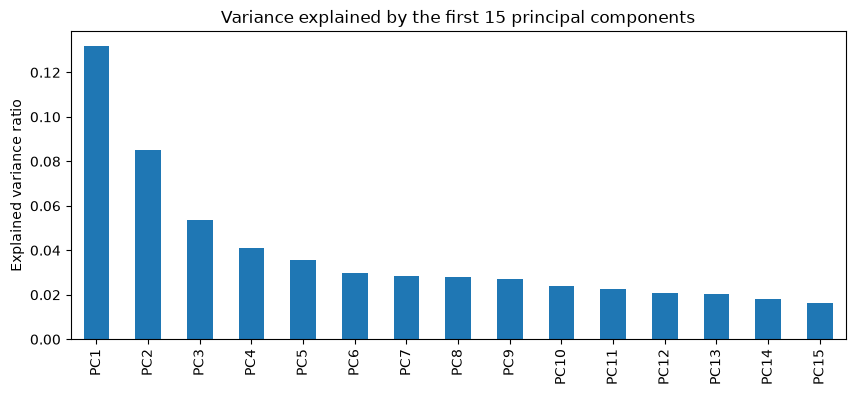

In [6]:
pca98 = PCA(n_components=0.98, svd_solver="full", random_state=42)
Z98 = pca98.fit_transform(X_minmax)
print("Components kept:", pca98.n_components_, "of", X.shape[1], "features")

evr = pd.Series(pca98.explained_variance_ratio_, index=[f"PC{i+1}" for i in range(pca98.n_components_)])
print(evr.head(15))

evr.head(15).plot(kind="bar", figsize=(10, 4))
plt.ylabel("Explained variance ratio")
plt.title("Variance explained by the first 15 principal components")
plt.show()

**Interpretation**

With 98% of the variance, PCA keeps 123 of the 250 features, so I only remove about half of the dimensions. PC1 explains 13.2% of the variance and PC2 8.5%, together about 21.7%. After that the values drop slowly (PC3 5.3%, PC4 4.1%, PC5 3.5%) and from PC6 on every component explains less than 3%. The first 10 components together explain about 48% and the first 15 about 58%.

This means that there is no small group of components that carries most of the information. The variance is spread over many components, which is probably because a lot of the 250 features are one-hot columns that are not strongly correlated with each other.

### 1.3 Number of components for 98%, 95%, 90% and 80%

Now I want to know how many components are necessary for each of the four variance thresholds. For this, I fit a PCA with all components and calculate the cumulative sum of `explained_variance_ratio_`. With `np.searchsorted` I then look for the first component where the cumulative variance reaches the threshold.

I do this for both scalings, so I can already see whether min-max scaling and standardization need a different number of components. The plots show the cumulative variance as a function of the number of components. The dashed lines mark the four thresholds and the number of components needed for each of them.

min-max {0.98: 123, 0.95: 88, 0.9: 63, 0.8: 39}
standardization {0.98: 181, 0.95: 160, 0.9: 138, 0.8: 106}


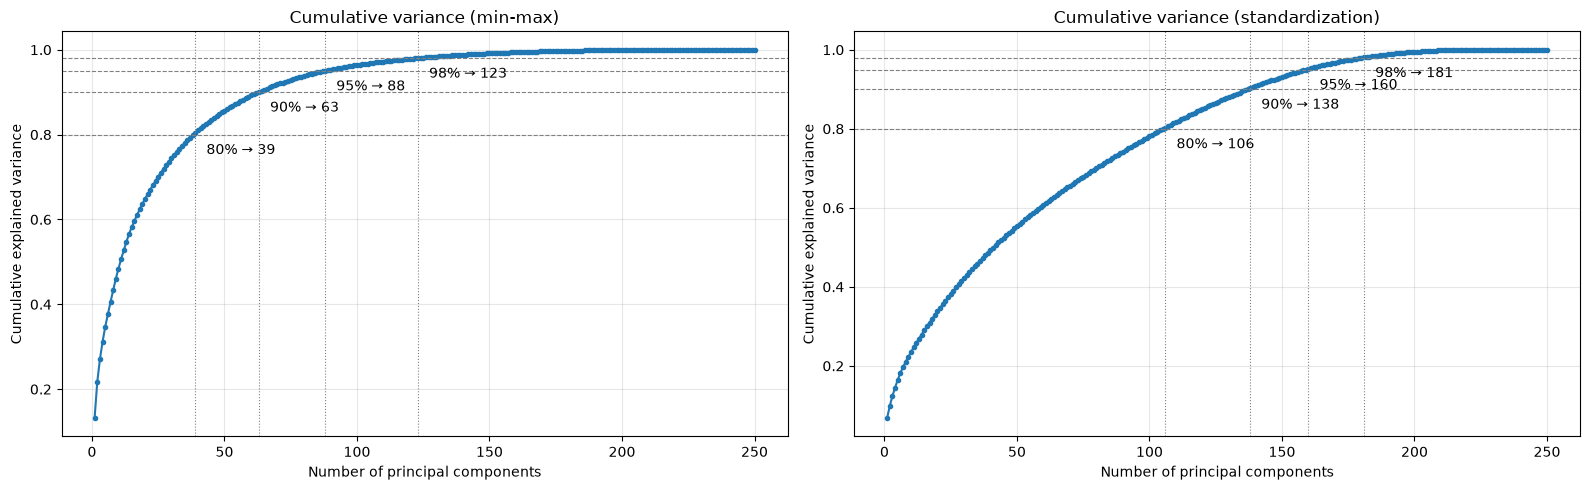

In [7]:
thresholds = [0.98, 0.95, 0.90, 0.80]

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for ax, (name, Xs) in zip(axes, {"min-max": X_minmax, "standardization": X_std}.items()):
    full = PCA(svd_solver="full", random_state=42).fit(Xs)
    cum = np.cumsum(full.explained_variance_ratio_)
    n_per = {t: int(np.searchsorted(cum, t) + 1) for t in thresholds}
    print(name, n_per)

    ax.plot(range(1, len(cum) + 1), cum, marker=".")
    for t, n in n_per.items():
        ax.axhline(t, color="gray", linestyle="--", linewidth=0.8)
        ax.axvline(n, color="gray", linestyle=":", linewidth=0.8)
        ax.annotate(f"{int(t * 100)}% → {n}", (n, t), textcoords="offset points", xytext=(8, -14))
    ax.set_xlabel("Number of principal components")
    ax.set_ylabel("Cumulative explained variance")
    ax.set_title(f"Cumulative variance ({name})")
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Interpretation**

The number of principal components needed for each threshold:

| Variance | min-max | standardization |
|---|---|---|
| 98% | 123 | 181 |
| 95% | 88 | 160 |
| 90% | 63 | 138 |
| 80% | 39 | 106 |

Standardization needs a lot more components, for 80% almost three times as many (106 instead of 39). The cumulative variance curve is also much flatter, and PC1 explains only roughly 7% instead of 13%.

As I understand, the reason is the scaling. With standardization every feature gets a variance of 1, so all 250 features count equally, including one-hot columns of rare categories. The variance is spread over many directions. With min-max scaling the variance of a feature depends on how much it spreads inside [0, 1], so features with a few large outliers get squeezed and contribute less, and fewer directions are enough. I will see in part 2 if this also changes the clusters.

### 1.4 PCA on the standardized data

For part 2, I also need the reduced dataset based on the standardized features. I fit a second PCA with 98% of the variance on `X_std`. I keep the min-max version `pca98` and this one `pca98_std` separate, so I can compare the k-means results of both scalings later.

In [8]:
pca98_std = PCA(n_components=0.98, svd_solver="full", random_state=42)
Z98_std = pca98_std.fit_transform(X_std)
print("Components kept:", pca98_std.n_components_)

Components kept: 181


### 1.5 Before and after PCA

To get a better idea of what PCA does with the data, I plot the houses before and after the transformation. On the left, I use two of the original min-max scaled features (`Gr Liv Area` and `Overall Qual`), on the right the first two principal components. The points are colored by `PriceClass`.

I want to see whether the price classes are already more visible in the first two components than in two single features. The price classes are only used for the colors, PCA itself does not know about them.

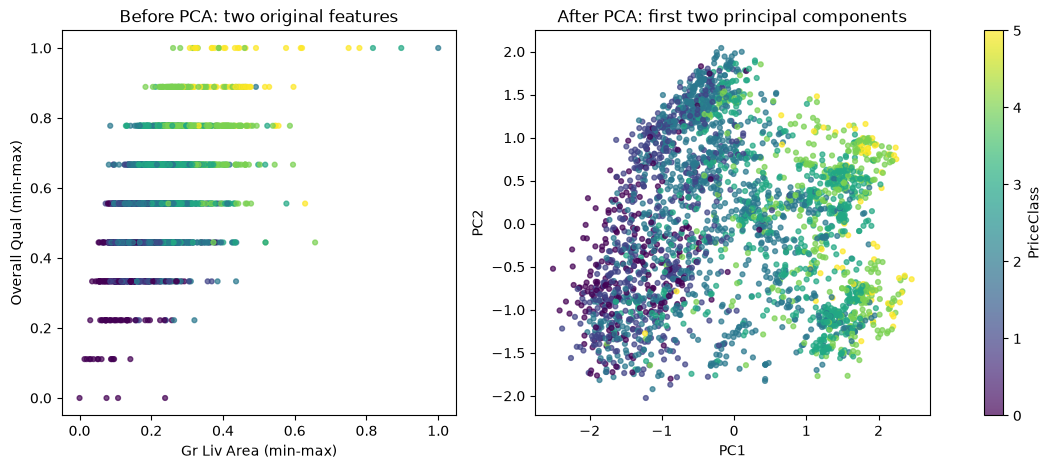

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sc = axes[0].scatter(X_minmax["Gr Liv Area"], X_minmax["Overall Qual"], c=y, cmap="viridis", s=12, alpha=0.7)
axes[0].set_xlabel("Gr Liv Area (min-max)")
axes[0].set_ylabel("Overall Qual (min-max)")
axes[0].set_title("Before PCA: two original features")

axes[1].scatter(Z98[:, 0], Z98[:, 1], c=y, cmap="viridis", s=12, alpha=0.7)
axes[1].set_xlabel("PC1")
axes[1].set_ylabel("PC2")
axes[1].set_title("After PCA: first two principal components")

fig.colorbar(sc, ax=axes, label="PriceClass")
plt.show()

**Interpretation**

On the left, `Overall Qual` and `Gr Liv Area` already show a trend: the higher the quality and the bigger the area, the higher the price class. However, the price classes overlap a lot. Inside one stripe of `Overall Qual` the colors change along the x axis, and one single feature does not separate the classes.

On the right, PC1 separates the price classes better. The cheap houses (dark purple) are on the left, the expensive houses (green and yellow) are on the right. PC2 does not seem to be related to the price, since all colors are mixed along this axis. The classes still overlap in the middle, so PCA does not separate them completely.

I also see two denser groups on the right side, one around PC2 = 0.5 to 1 and one around PC2 = -1. Maybe k-means will find these groups in part 2.

### 1.6 Loadings

To see which features influence the most important principal components, I calculate the loadings with `pca.components_.T * np.sqrt(pca.explained_variance_)`. Each row is a feature and each column a principal component. A large absolute value means that the feature has a strong influence on this component. The sign shows the direction: features with the same sign move together along the component, features with opposite signs work against each other.

I first plot the 15 features with the largest absolute loading for PC1, PC2 and PC3 (blue is positive, red is negative). Then I use a heatmap for the first five components and the 25 most influential features, to see which features show up in more than one component.

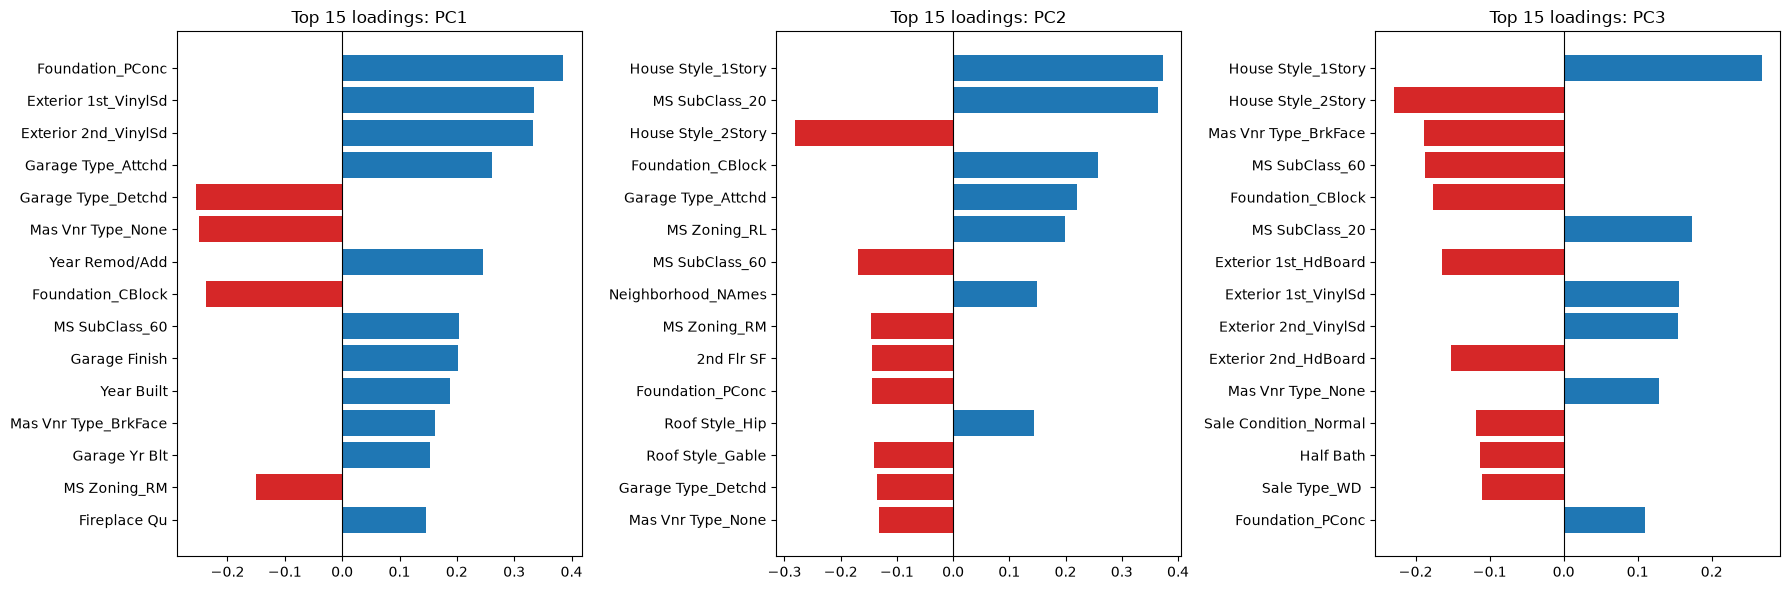

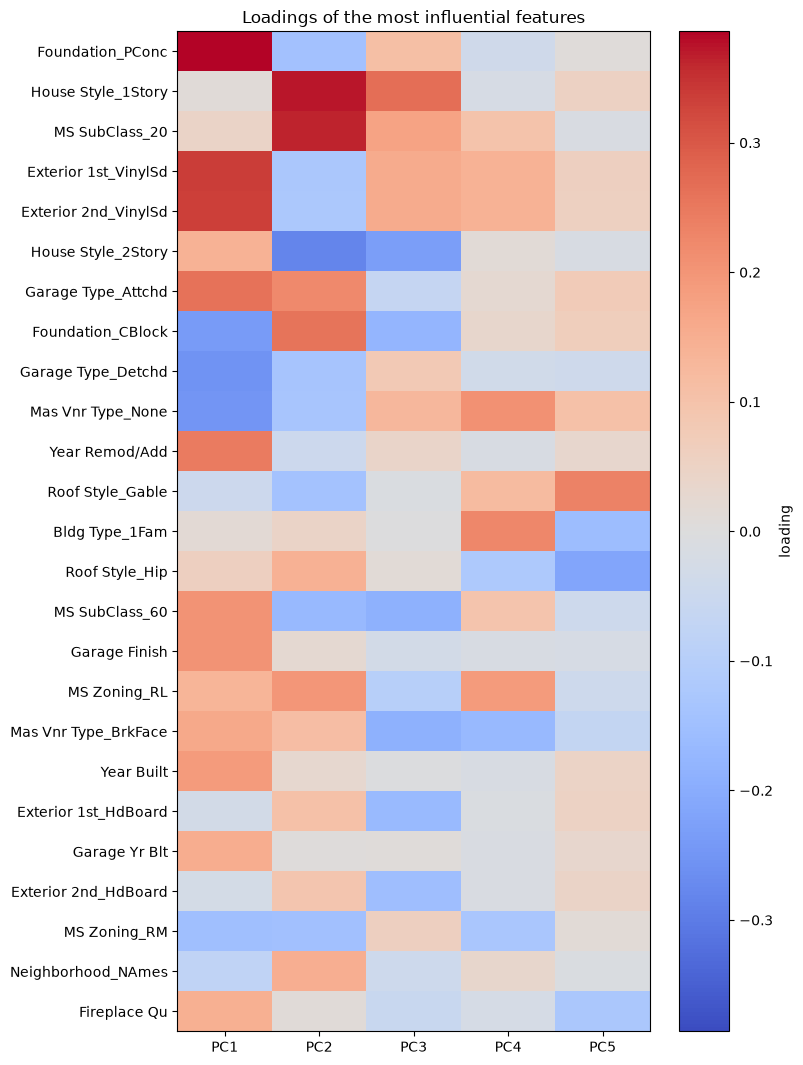

In [10]:
loadings = pd.DataFrame(
    pca98.components_.T * np.sqrt(pca98.explained_variance_),
    index=X.columns,
    columns=[f"PC{i+1}" for i in range(pca98.n_components_)],
)

top = 15
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for ax, pc in zip(axes, ["PC1", "PC2", "PC3"]):
    s = loadings[pc]
    s = s.reindex(s.abs().sort_values(ascending=False).index[:top])[::-1]
    ax.barh(s.index, s.values, color=np.where(s.values >= 0, "tab:blue", "tab:red"))
    ax.axvline(0, color="black", linewidth=0.8)
    ax.set_title(f"Top {top} loadings: {pc}")
plt.tight_layout()
plt.show()

n_pcs, n_feat = 5, 25
sub = loadings.iloc[:, :n_pcs]
sub = sub.loc[sub.abs().max(axis=1).sort_values(ascending=False).index[:n_feat]]
lim = sub.abs().values.max()
plt.figure(figsize=(8, 0.35 * n_feat + 2))
plt.imshow(sub.values, cmap="coolwarm", aspect="auto", vmin=-lim, vmax=lim)
plt.colorbar(label="loading")
plt.xticks(range(n_pcs), sub.columns)
plt.yticks(range(len(sub)), sub.index)
plt.title("Loadings of the most influential features")
plt.tight_layout()
plt.show()

**Interpretation**

- **PC1:** The positive loadings are `Foundation_PConc`, `Exterior 1st_VinylSd`, `Exterior 2nd_VinylSd`, `Garage Type_Attchd`, `Year Remod/Add`, `Year Built`, `Garage Yr Blt` and `Garage Finish`. The negative ones are `Garage Type_Detchd`, `Mas Vnr Type_None`, `Foundation_CBlock` and `MS Zoning_RM`. Since the three year features are all positive, PC1 seems to describe how new the house is. Maybe this is why PC1 already separates the price classes in the scatter plot, because newer houses are more expensive.
- **PC2:** `House Style_1Story` and `MS SubClass_20` are positive, `House Style_2Story`, `MS SubClass_60` and `2nd Flr SF` are negative. This means that PC2 separates one-story from two-story houses.
- **PC3:** `House Style_1Story` is positive and `House Style_2Story` negative again, but there are also the exterior (`Exterior 1st_VinylSd` positive, `Exterior 1st_HdBoard` negative) and `Mas Vnr Type_BrkFace`. This one is harder to interpret.
- **PC4 and PC5:** In the heatmap, PC5 is mostly `Roof Style_Gable` against `Roof Style_Hip`, and PC4 has `Bldg Type_1Fam` and `Mas Vnr Type_None` as the largest loadings.

What I notice is that `Overall Qual` and `Gr Liv Area`, which I used for the plot before PCA, are not among the top loadings. Most of the top features are one-hot columns. I don't understand yet why, maybe because the continuous features with outliers get squeezed by the min-max scaling, as in 1.3.

Some features appear in more than one component, for example `Foundation_PConc` (strongly positive in PC1, negative in PC2) and `MS SubClass_60` (positive in PC1, negative in PC2 and PC3).

To back up the claim that PC1 is related to the price

In [11]:
print(np.corrcoef(Z98[:, 0], y)[0, 1], np.corrcoef(Z98[:, 1], y)[0, 1])

0.7518100470673498 0.03632711289004137
